# Thermal Intelligence: Causal Drivers and Predictive Optimization of Waste Heat Recovery at Exascale HPC Data Centers

**Data:** Frontier Supercomputer, Oak Ridge National Laboratory (ORNL)  
**Source:** Sun et al., *Nature Scientific Data*, October 2024  
**Dataset:** 49,869 observations at 10-minute intervals, full year 2023  

---

## Setup

Importing everything upfront. Using `statsmodels` for the causal work, `xgboost` and `sklearn` for the predictive model, and `shap` to connect the ML findings back to the causal story. `prophet` comes in later for time series forecasting.

In [1]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", 
                "pandas", "numpy", "matplotlib", "seaborn", 
                "statsmodels", "scikit-learn", "xgboost", 
                "shap", "scipy", "openpyxl", "-q"], check=True)
print("installed")


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


installed


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
import xgboost as xgb
import shap
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.dpi'] = 130
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

np.random.seed(42)

print("All imports successful.")

All imports successful.


/workspaces/thermal-intelligence-hpc/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Section 2: Data

The dataset comes from Sun et al. (2024), published in *Nature Scientific Data*. It covers the full 2023 operating year of the Frontier supercomputer at ORNL, which is the world's first exascale system. Observations are at 10-minute intervals across three cooling subloops, capturing coolant temperatures, flow rates, waste heat output, compute power, and PUE.

I chose this dataset specifically because it's real operational data from a peer-reviewed source, directly on the thermal recovery topic, and recent enough (2024 publication) to be relevant to current industry conversations around the EU Data Center Energy Efficiency Package and Germany's EnEfG mandate.

In [3]:
df = pd.read_excel('frontier_facility_data.xlsx', sheet_name='Frontier2023', skiprows=1)
df.columns = [
    'timestamp',
    'subloop1_return_temp_c', 'subloop1_flow_gpm',
    'subloop2_return_temp_c', 'subloop2_flow_gpm',
    'subloop3_return_temp_c', 'subloop3_flow_gpm',
    'avg_return_temp_c', 'supply_temp_c', 'total_flow_gpm',
    'subloop1_waste_heat_mw', 'subloop2_waste_heat_mw', 'subloop3_waste_heat_mw',
    'total_waste_heat_mw',
    'compute_power_mw', 'accessory_power_mw', 'total_power_mw',
    'pue'
]

df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.set_index('timestamp').sort_index()

print(f"Shape: {df.shape}")
print(f"Date range: {df.index.min()} to {df.index.max()}")
print(f"Missing values:\n{df.isnull().sum()}")

Shape: (49869, 17)
Date range: 2023-01-01 00:00:00 to 2023-12-31 23:50:00
Missing values:
subloop1_return_temp_c      0
subloop1_flow_gpm           0
subloop2_return_temp_c      0
subloop2_flow_gpm           0
subloop3_return_temp_c      0
subloop3_flow_gpm           0
avg_return_temp_c         122
supply_temp_c               0
total_flow_gpm              0
subloop1_waste_heat_mw      0
subloop2_waste_heat_mw      0
subloop3_waste_heat_mw      0
total_waste_heat_mw         0
compute_power_mw            0
accessory_power_mw          0
total_power_mw              0
pue                         0
dtype: int64


### Data Quality

Only 122 missing values out of 49,869 rows, all in `avg_return_temp_c`. Since this column is just the average of the three subloop return temps, I'll impute it directly from those rather than dropping rows or using a generic fill method.

In [4]:
# impute avg_return_temp_c from the three subloop return temps
df['avg_return_temp_c'] = df['avg_return_temp_c'].fillna(
    (df['subloop1_return_temp_c'] + 
     df['subloop2_return_temp_c'] + 
     df['subloop3_return_temp_c']) / 3
)

# add time features we'll need later
df['month'] = df.index.month
df['hour'] = df.index.hour
df['day_of_week'] = df.index.dayofweek
df['quarter'] = df.index.quarter

print(f"Missing values after imputation: {df['avg_return_temp_c'].isnull().sum()}")
print(f"\nKey stats:")
print(df[['total_waste_heat_mw', 'compute_power_mw', 
          'avg_return_temp_c', 'pue']].describe().round(3))

Missing values after imputation: 0

Key stats:
       total_waste_heat_mw  compute_power_mw  avg_return_temp_c        pue
count            49869.000         49869.000          49869.000  49869.000
mean                 9.093            11.603             31.167      1.055
std                  3.093             3.289              4.353      0.018
min                  0.000             0.765              7.651      1.023
25%                  6.931             9.104             28.999      1.046
50%                  8.586            10.988             31.797      1.053
75%                 10.758            13.482             33.799      1.061
max                 26.335            27.699             45.622      1.535


### Quick Sanity Check
Before diving into full EDA, a quick look at the relationship between compute power and waste heat to make sure the data makes physical sense.

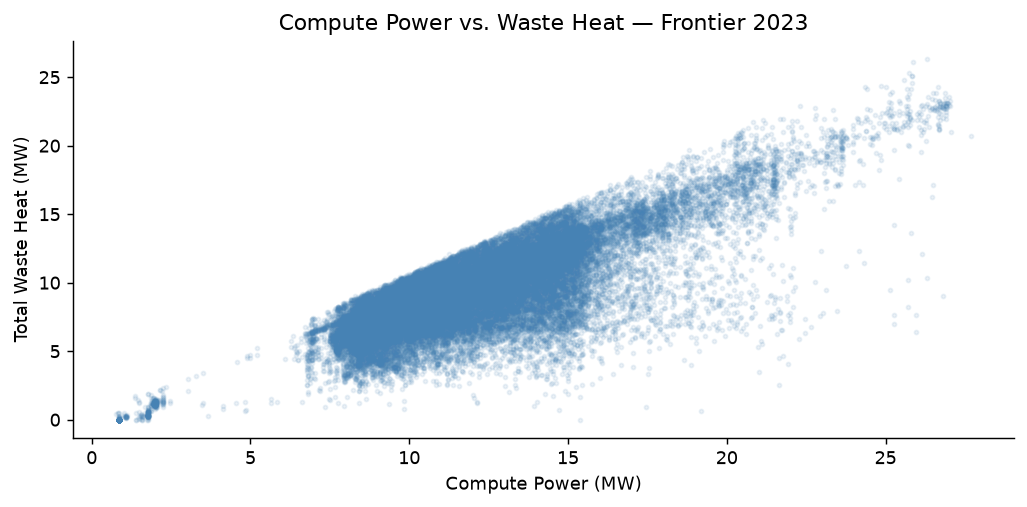

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(df['compute_power_mw'], df['total_waste_heat_mw'], 
           alpha=0.1, s=5, color='steelblue')
ax.set_xlabel('Compute Power (MW)')
ax.set_ylabel('Total Waste Heat (MW)')
ax.set_title('Compute Power vs. Waste Heat — Frontier 2023')
plt.tight_layout()
plt.savefig('../figures/sanity_check_scatter.png', dpi=130)
plt.show()

**What this tells us:** Strong linear relationship between compute power and waste heat, which is physically expected and confirms data integrity. The vertical spread at each compute level is the interesting signal: same workload, different recoverable heat. That variance is what the causal analysis will decompose.

The cluster of low-power observations (1-5 MW) likely corresponds to maintenance windows and scheduled downtime. I'll keep these in the dataset rather than filtering them out. They're real operating states and removing them would bias the recovery viability analysis in Section 5.

## Section 3: Exploratory Data Analysis

### 3.1 Full Year Time Series

Looking at waste heat, compute power, and PUE across all of 2023 to understand seasonality and operating patterns.

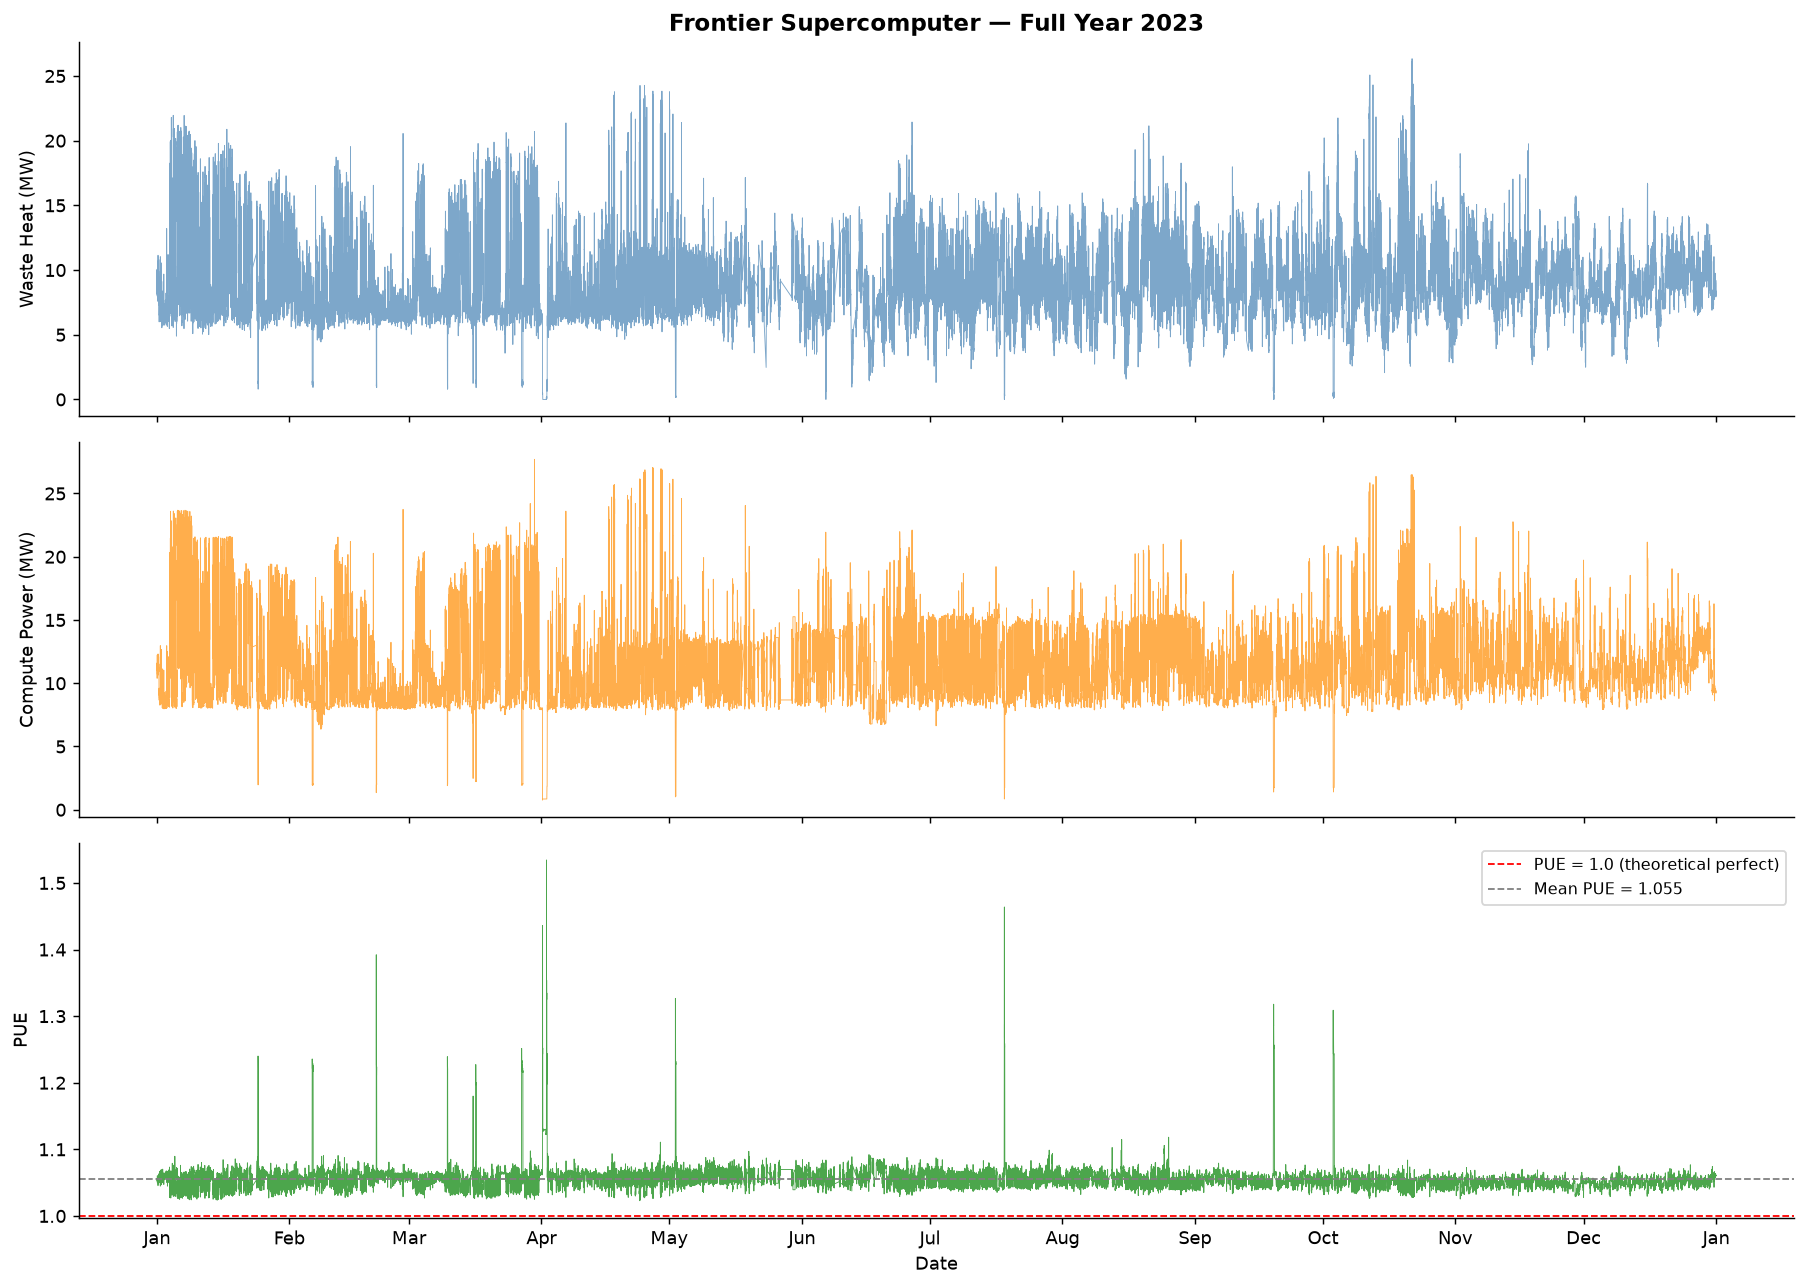

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

# Waste heat
axes[0].plot(df.index, df['total_waste_heat_mw'], 
             color='steelblue', lw=0.5, alpha=0.7)
axes[0].set_ylabel('Waste Heat (MW)')
axes[0].set_title('Frontier Supercomputer — Full Year 2023', fontsize=13, fontweight='bold')

# Compute power
axes[1].plot(df.index, df['compute_power_mw'], 
             color='darkorange', lw=0.5, alpha=0.7)
axes[1].set_ylabel('Compute Power (MW)')

# PUE
axes[2].plot(df.index, df['pue'], 
             color='green', lw=0.5, alpha=0.7)
axes[2].axhline(1.0, color='red', linestyle='--', lw=1, label='PUE = 1.0 (theoretical perfect)')
axes[2].axhline(df['pue'].mean(), color='gray', linestyle='--', lw=1, 
                label=f'Mean PUE = {df["pue"].mean():.3f}')
axes[2].set_ylabel('PUE')
axes[2].set_xlabel('Date')
axes[2].legend(fontsize=9)

# format x axis
axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%b'))
axes[2].xaxis.set_major_locator(mdates.MonthLocator())

plt.tight_layout()
plt.savefig('../figures/full_year_timeseries.png', dpi=130, bbox_inches='tight')
plt.show()

**Key observations:**
- Waste heat and compute power are tightly coupled throughout the year, consistent with thermodynamic expectations
- Sharp drops to near-zero in both panels correspond to scheduled maintenance windows — these are real operating states, not anomalies
- PUE spikes during maintenance windows are a measurement artifact: cooling systems remain partially active while compute drops, inflating the ratio temporarily
- No strong seasonal pattern in waste heat output. Liquid cooling at this scale appears thermally decoupled from ambient conditions, unlike air-cooled facilities

This last point is operationally significant: it suggests **waste heat recovery at Frontier would be viable year-round, not just in winter months.**

### 3.2 Seasonality and Monthly Patterns

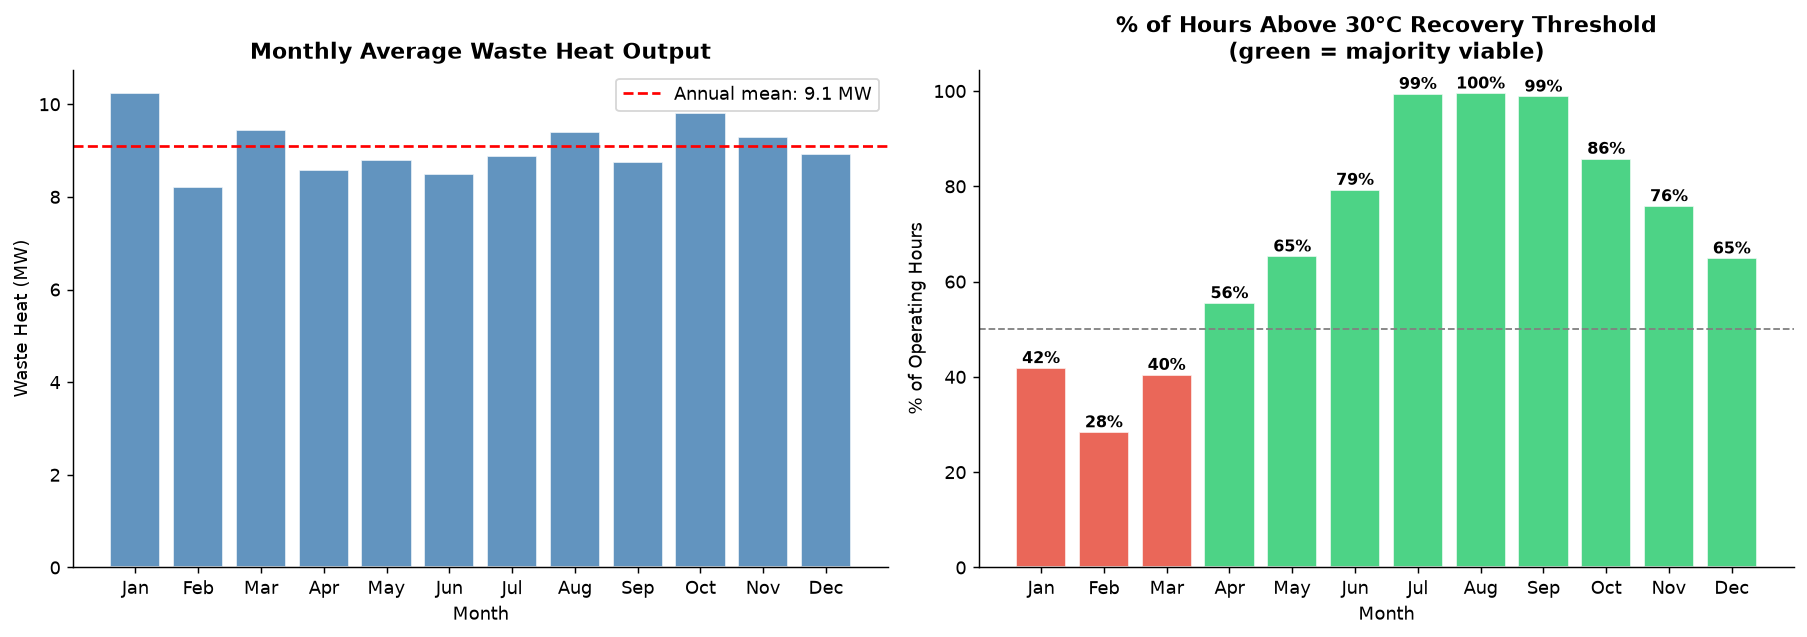


Overall % of hours above 30°C threshold: 69.7%


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Monthly average waste heat
monthly = df.groupby('month')[['total_waste_heat_mw', 'compute_power_mw', 'avg_return_temp_c']].mean()
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

bars = axes[0].bar(month_names, monthly['total_waste_heat_mw'], 
                    color='steelblue', edgecolor='white', alpha=0.85)
axes[0].axhline(df['total_waste_heat_mw'].mean(), color='red', 
                linestyle='--', lw=1.5, label=f'Annual mean: {df["total_waste_heat_mw"].mean():.1f} MW')
axes[0].set_title('Monthly Average Waste Heat Output', fontweight='bold')
axes[0].set_ylabel('Waste Heat (MW)')
axes[0].set_xlabel('Month')
axes[0].legend()

# % of hours above 30C threshold by month
df['above_threshold'] = (df['avg_return_temp_c'] >= 30).astype(int)
monthly_viable = df.groupby('month')['above_threshold'].mean() * 100

axes[1].bar(month_names, monthly_viable.values,
            color=['#2ecc71' if v >= 50 else '#e74c3c' for v in monthly_viable.values],
            edgecolor='white', alpha=0.85)
axes[1].axhline(50, color='gray', linestyle='--', lw=1)
axes[1].set_title('% of Hours Above 30°C Recovery Threshold\n(green = majority viable)', 
                   fontweight='bold')
axes[1].set_ylabel('% of Operating Hours')
axes[1].set_xlabel('Month')

for i, v in enumerate(monthly_viable.values):
    axes[1].text(i, v + 1, f'{v:.0f}%', ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig('../figures/seasonality.png', dpi=130, bbox_inches='tight')
plt.show()

print(f"\nOverall % of hours above 30°C threshold: {df['above_threshold'].mean()*100:.1f}%")

**Key finding:** Waste heat output is thermally stable year-round (~9 MW average every month), but heat pump *viability* is highly seasonal — driven by coolant return temperatures, not by waste heat volume. Jan-Mar fall below the 30°C threshold majority of the time, while Jun-Aug are viable nearly 100% of hours.

This has a direct operational implication: a heat pump system sized for summer operation would sit underutilized in winter. A smart activation framework (seen in Section 7) is therefore not just a nice-to-have but a genuine operational necessity to maximize ROI on the capital investment.

**Overall: 69.7% of 2023 operating hours exceeded the recovery threshold.**

### 3.3 Subloop Breakdown
Which of the three cooling loops contributes most to recoverable waste heat?

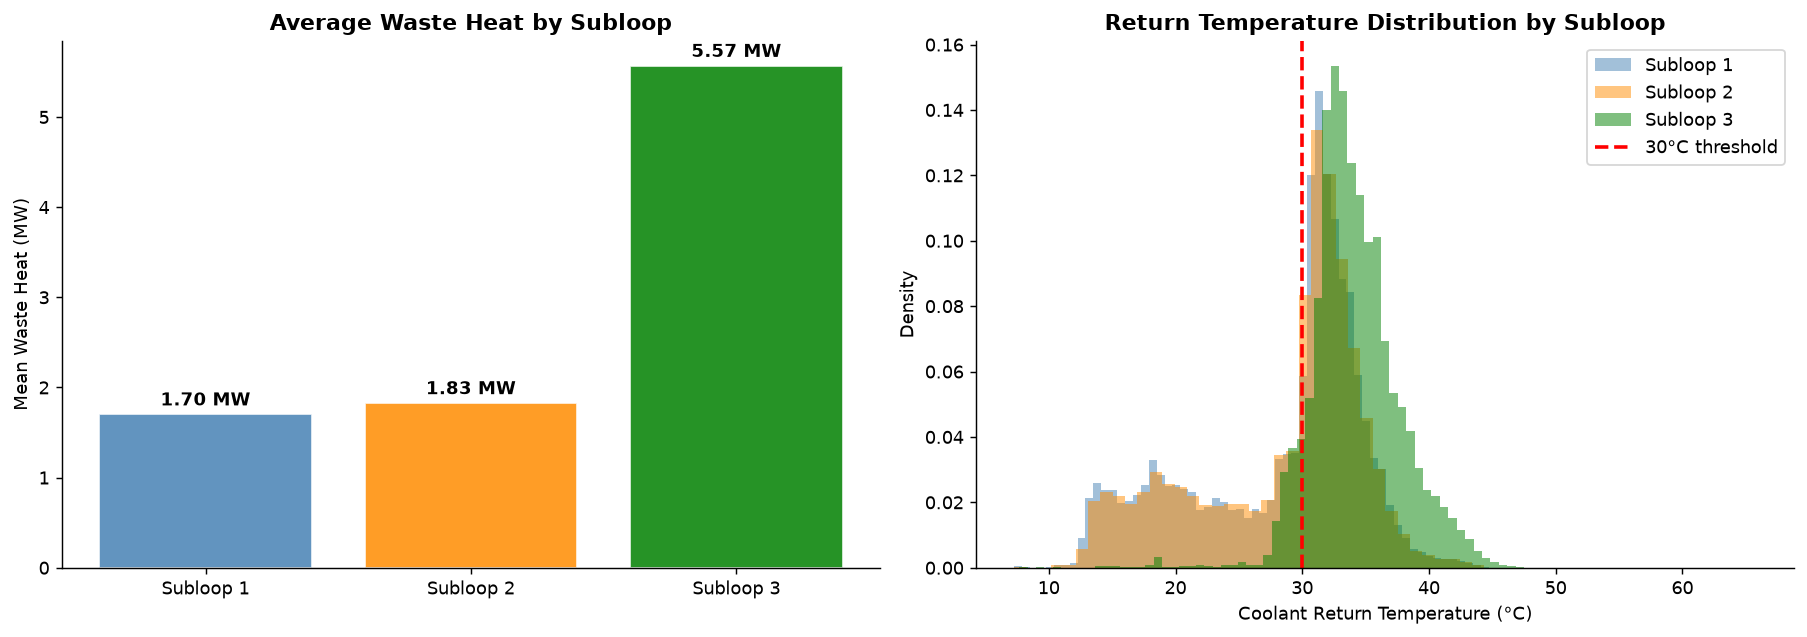

Subloop 1: 1.70 MW (18.7% of total)
Subloop 2: 1.83 MW (20.1% of total)
Subloop 3: 5.57 MW (61.2% of total)


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Average waste heat contribution by subloop
subloop_means = {
    'Subloop 1': df['subloop1_waste_heat_mw'].mean(),
    'Subloop 2': df['subloop2_waste_heat_mw'].mean(),
    'Subloop 3': df['subloop3_waste_heat_mw'].mean()
}

colors = ['steelblue', 'darkorange', 'green']
axes[0].bar(subloop_means.keys(), subloop_means.values(), 
            color=colors, edgecolor='white', alpha=0.85)
axes[0].set_title('Average Waste Heat by Subloop', fontweight='bold')
axes[0].set_ylabel('Mean Waste Heat (MW)')
for i, (k, v) in enumerate(subloop_means.items()):
    axes[0].text(i, v + 0.1, f'{v:.2f} MW', ha='center', fontweight='bold', fontsize=10)

# Return temp distributions by subloop
for i, (col, label, color) in enumerate([
    ('subloop1_return_temp_c', 'Subloop 1', 'steelblue'),
    ('subloop2_return_temp_c', 'Subloop 2', 'darkorange'),
    ('subloop3_return_temp_c', 'Subloop 3', 'green')
]):
    axes[1].hist(df[col], bins=60, alpha=0.5, color=color, label=label, density=True)

axes[1].axvline(30, color='red', linestyle='--', lw=2, label='30°C threshold')
axes[1].set_title('Return Temperature Distribution by Subloop', fontweight='bold')
axes[1].set_xlabel('Coolant Return Temperature (°C)')
axes[1].set_ylabel('Density')
axes[1].legend()

plt.tight_layout()
plt.savefig('../figures/subloop_breakdown.png', dpi=130, bbox_inches='tight')
plt.show()

# subloop share of total
total = sum(subloop_means.values())
for k, v in subloop_means.items():
    print(f"{k}: {v:.2f} MW ({v/total*100:.1f}% of total)")

**Subloop 3 dominates waste heat output at 61.2% of total** (5.57 MW average vs. 1.70 and 1.83 MW for Subloops 1 and 2). The temperature distribution plot explains why. Subloop 3 runs consistently hotter, with its distribution centered well above the 30°C recovery threshold. Subloops 1 and 2 cluster around and below threshold, making them lower-priority targets for heat recovery infrastructure investment.

For an operator evaluating where to install heat exchangers, this analysis has an immediate practical answer: prioritize Subloop 3.

### 3.4 Correlation Heatmap

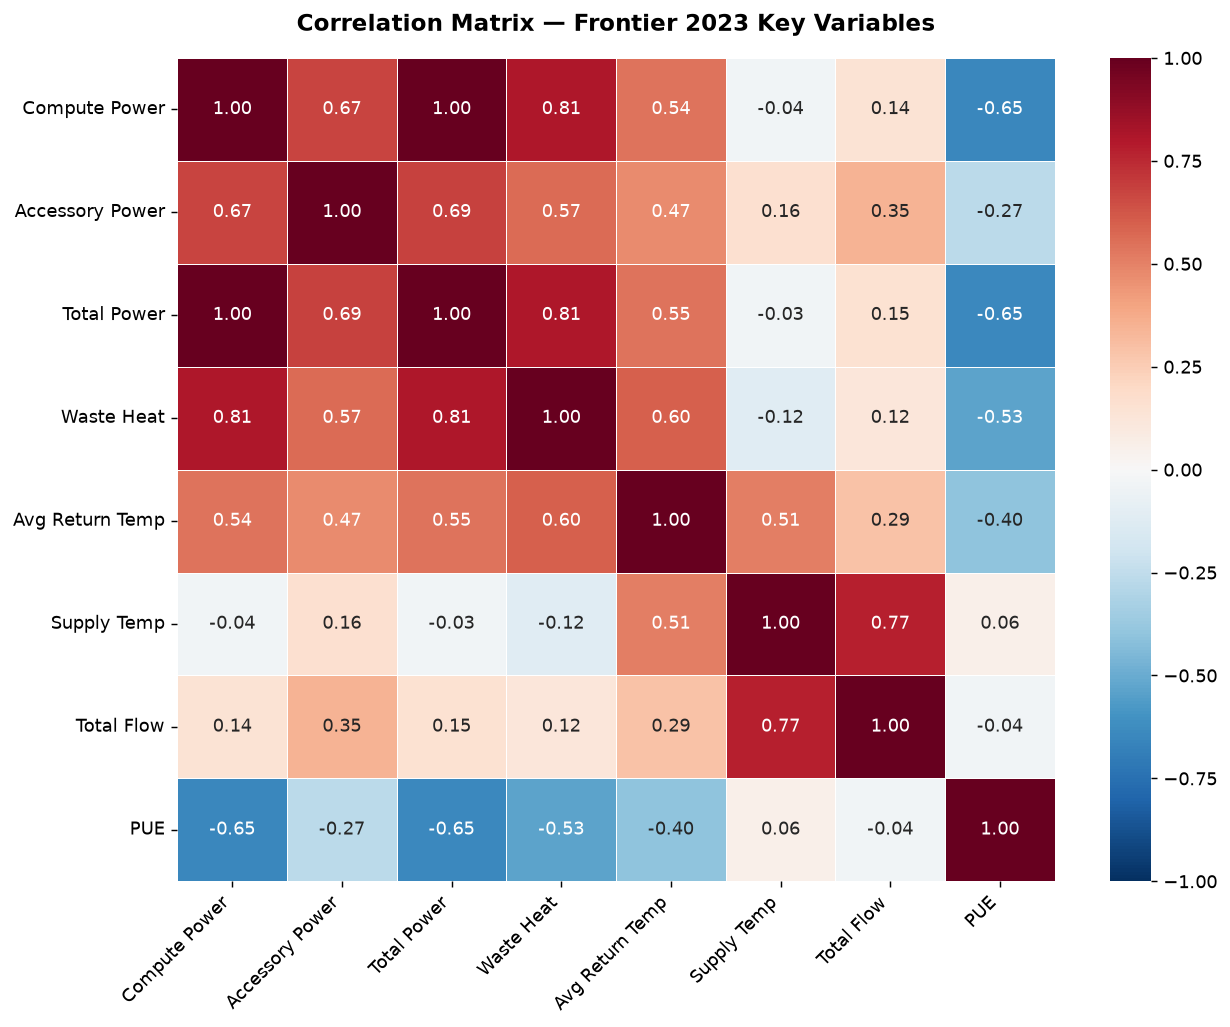

In [9]:
corr_cols = [
    'compute_power_mw', 'accessory_power_mw', 'total_power_mw',
    'total_waste_heat_mw', 'avg_return_temp_c', 'supply_temp_c',
    'total_flow_gpm', 'pue'
]

corr = df[corr_cols].corr()

# cleaner labels for display
labels = [
    'Compute Power', 'Accessory Power', 'Total Power',
    'Waste Heat', 'Avg Return Temp', 'Supply Temp',
    'Total Flow', 'PUE'
]

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

sns.heatmap(corr, 
            annot=True, 
            fmt='.2f',
            cmap='RdBu_r',
            center=0,
            vmin=-1, vmax=1,
            xticklabels=labels,
            yticklabels=labels,
            ax=ax,
            linewidths=0.5,
            annot_kws={'size': 10})

ax.set_title('Correlation Matrix — Frontier 2023 Key Variables', 
             fontweight='bold', fontsize=13, pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('../figures/correlation_heatmap.png', dpi=130, bbox_inches='tight')
plt.show()

**Key correlations:**
- Compute power and waste heat: r = 0.81 — strong positive relationship, thermodynamically expected
- PUE and compute power: r = -0.65 — counterintuitive at first glance, but makes sense: Frontier is most *efficient* (low PUE) when running at high compute load. The PUE spikes we saw in the time series correspond to low-compute maintenance windows where cooling overhead is disproportionately high
- Supply temp and total flow: r = 0.77 — the cooling system actively compensates for higher inlet temperatures by increasing flow rate
- Accessory power and waste heat: r = 0.57, notably lower than compute power's 0.81 — this partial decoupling is what makes accessory power a candidate instrumental variable in Section 4

### 3.5 Hourly Patterns and Operating States

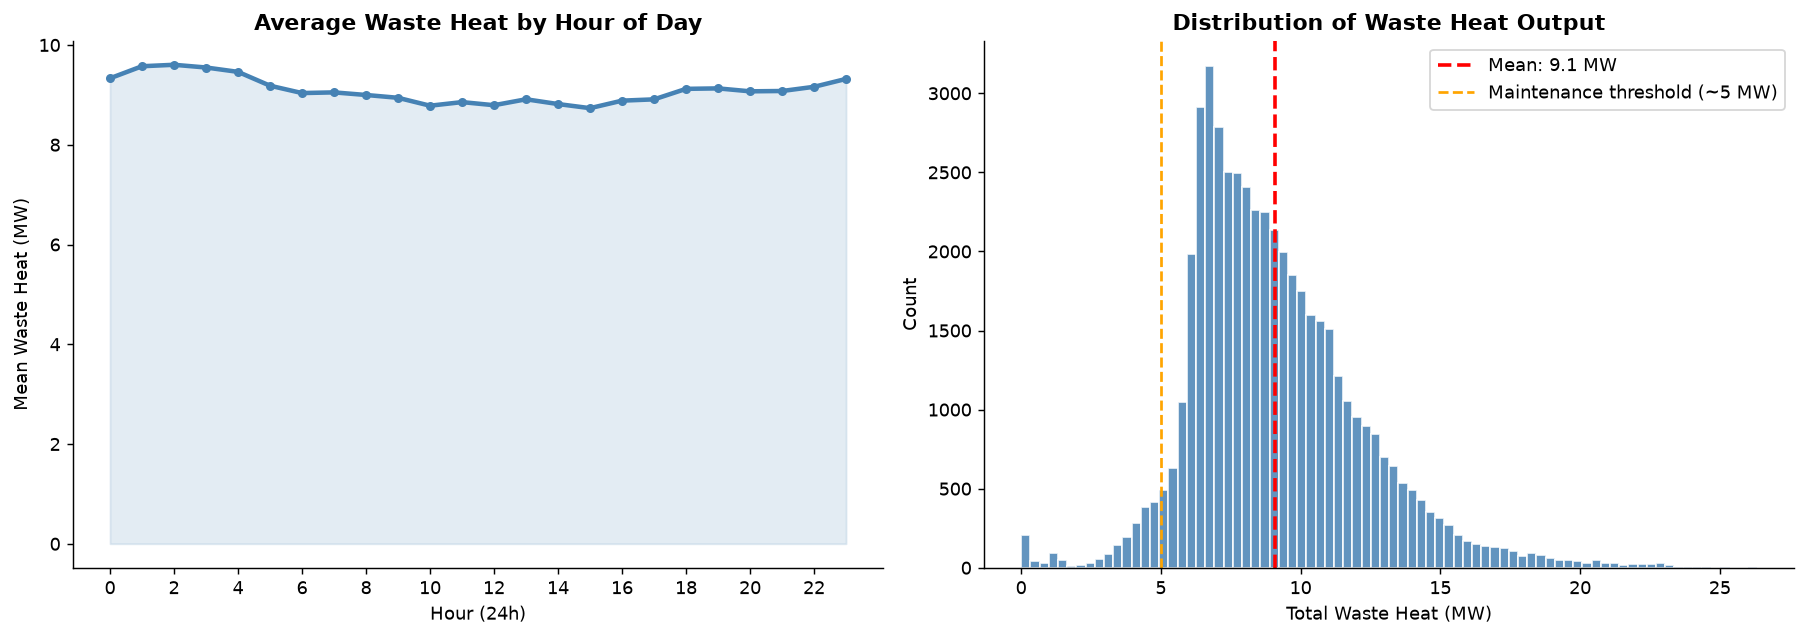

Normal operations (>=5 MW waste heat): 95.7% of observations
Maintenance/low-power states (<5 MW):  4.3% of observations


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Average waste heat by hour of day
hourly = df.groupby('hour')['total_waste_heat_mw'].mean()
axes[0].plot(hourly.index, hourly.values, 
             color='steelblue', lw=2.5, marker='o', markersize=4)
axes[0].fill_between(hourly.index, hourly.values, 
                      alpha=0.15, color='steelblue')
axes[0].set_title('Average Waste Heat by Hour of Day', fontweight='bold')
axes[0].set_xlabel('Hour (24h)')
axes[0].set_ylabel('Mean Waste Heat (MW)')
axes[0].set_xticks(range(0, 24, 2))

# Distribution of total waste heat — show operating states
axes[1].hist(df['total_waste_heat_mw'], bins=80, 
             color='steelblue', edgecolor='white', alpha=0.85)
axes[1].axvline(df['total_waste_heat_mw'].mean(), 
                color='red', linestyle='--', lw=2,
                label=f'Mean: {df["total_waste_heat_mw"].mean():.1f} MW')
axes[1].axvline(5, color='orange', linestyle='--', lw=1.5,
                label='Maintenance threshold (~5 MW)')
axes[1].set_title('Distribution of Waste Heat Output', fontweight='bold')
axes[1].set_xlabel('Total Waste Heat (MW)')
axes[1].set_ylabel('Count')
axes[1].legend()

plt.tight_layout()
plt.savefig('../figures/hourly_patterns.png', dpi=130, bbox_inches='tight')
plt.show()

# operating state breakdown
normal_ops = (df['total_waste_heat_mw'] >= 5).mean() * 100
maintenance = (df['total_waste_heat_mw'] < 5).mean() * 100
print(f"Normal operations (>=5 MW waste heat): {normal_ops:.1f}% of observations")
print(f"Maintenance/low-power states (<5 MW):  {maintenance:.1f}% of observations")

In [12]:
import os
os.makedirs('figures', exist_ok=True)

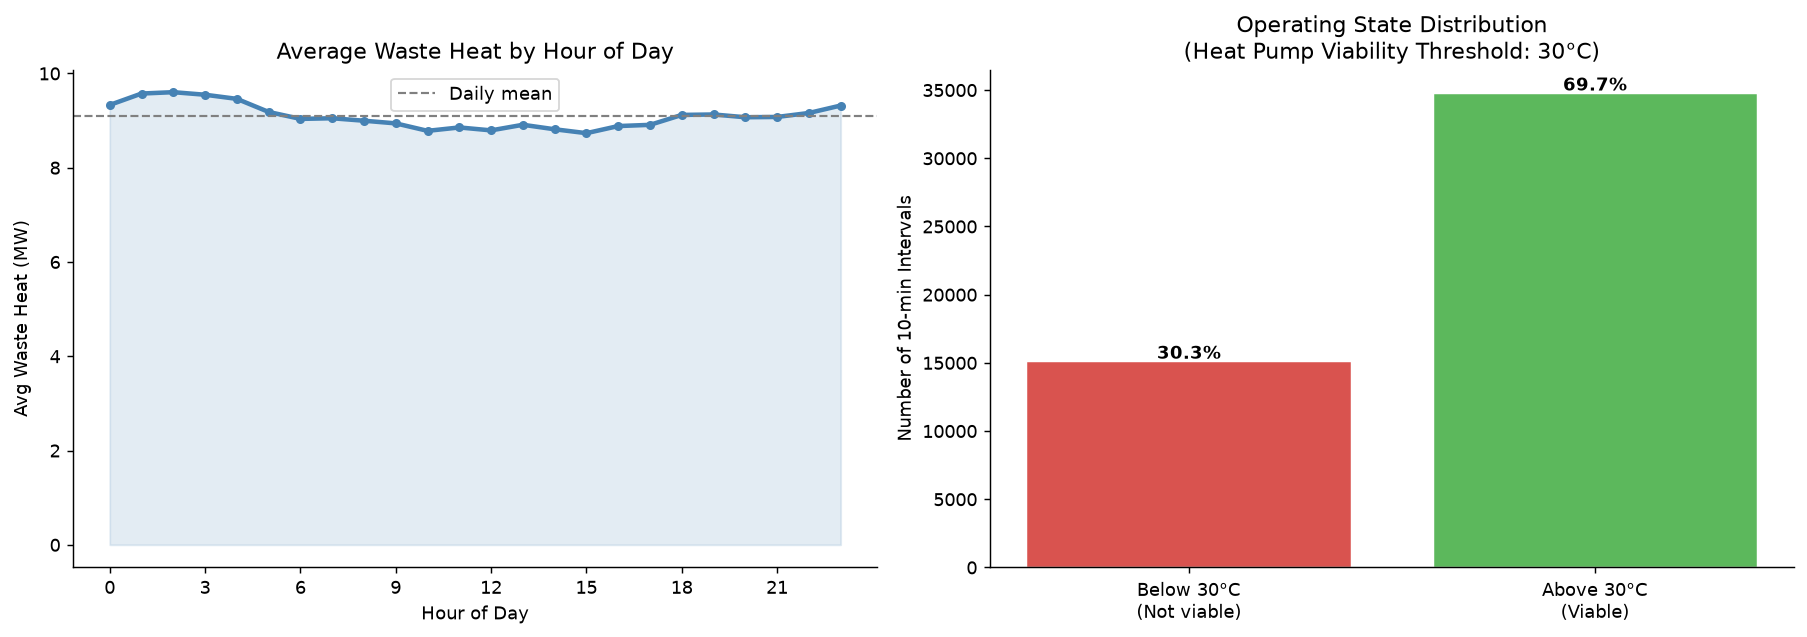

Section 3 complete.


In [13]:
# Section 3: Hourly patterns and operating states
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Average waste heat by hour of day
hourly = df.groupby('hour')['total_waste_heat_mw'].mean()
axes[0].plot(hourly.index, hourly.values,
             color='steelblue', lw=2.5, marker='o', markersize=4)
axes[0].fill_between(hourly.index, hourly.values, alpha=0.15, color='steelblue')
axes[0].axhline(y=hourly.mean(), color='gray', linestyle='--', lw=1.2, label='Daily mean')
axes[0].set_xlabel('Hour of Day')
axes[0].set_ylabel('Avg Waste Heat (MW)')
axes[0].set_title('Average Waste Heat by Hour of Day')
axes[0].set_xticks(range(0, 24, 3))
axes[0].legend()

# Operating state distribution: above/below 30°C threshold
df['recovery_viable'] = df['avg_return_temp_c'] > 30
state_counts = df['recovery_viable'].value_counts()
labels = ['Below 30°C\n(Not viable)', 'Above 30°C\n(Viable)']
colors = ['#d9534f', '#5cb85c']
axes[1].bar(labels, [state_counts.get(False, 0), state_counts.get(True, 0)],
            color=colors, edgecolor='white', linewidth=0.8)
axes[1].set_ylabel('Number of 10-min Intervals')
axes[1].set_title('Operating State Distribution\n(Heat Pump Viability Threshold: 30°C)')
for i, v in enumerate([state_counts.get(False, 0), state_counts.get(True, 0)]):
    pct = v / len(df) * 100
    axes[1].text(i, v + 200, f'{pct:.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('figures/hourly_patterns.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()
print("Section 3 complete.")